In [9]:
from pathlib import Path
import os
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import train_test_split

from collections import Counter

In [10]:
INPUT_DIR = Path("/kaggle/input")

train_folders = list(INPUT_DIR.rglob("Train"))

dataset_candidates = []

for folder in train_folders:

    if not folder.is_dir():
        continue

    # Verifier la presence des classes
    expected_classes = [
        "Glioma",
        "Meningioma",
        "No Tumor",
        "Pituitary"
    ]

    if all((folder / class_name).is_dir()
           for class_name in expected_classes):

        dataset_candidates.append(folder.parent)

print("Datasets detectes :")

for dataset in dataset_candidates:
    print(dataset)

Datasets detectes :
/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes


In [11]:
DATASET_DIR = dataset_candidates[0]

TRAIN_SOURCE = DATASET_DIR / "Train"
VAL_SOURCE = DATASET_DIR / "Val"

CLASS_NAMES = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"
]

print("Dataset :",DATASET_DIR)
print("Train :",TRAIN_SOURCE)
print("Validation :",VAL_SOURCE)

Dataset : /kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes
Train : /kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Train
Validation : /kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Val


In [12]:
# virification du structure => chaque classe possede bien deux sous-dossiers
for split_name,split_dir in [("Train",TRAIN_SOURCE),("Val",VAL_SOURCE)]:
    if not split_dir.exists():
        print("doccier introuvalbe")
        continue

for class_name in CLASS_NAMES :
    class_dir = split_dir / class_name

    images_dir = class_dir / "images"
    labels_dir = class_dir / "labels"

    print(f"\nclasse : {class_name}")
    print("Images :", images_dir.exists())
    print("Labels :", labels_dir.exists())


classe : Glioma
Images : True
Labels : True

classe : Meningioma
Images : True
Labels : True

classe : No Tumor
Images : True
Labels : True

classe : Pituitary
Images : True
Labels : True


In [13]:
# le nombre d'images et labels
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

dataset_stats = []

for split_name, split_dir in [
    ("Train", TRAIN_SOURCE),
    ("Val", VAL_SOURCE)
]:

    for class_name in CLASS_NAMES:

        images_dir = split_dir / class_name / "images"
        labels_dir = split_dir / class_name / "labels"

        images = (
            [p for p in images_dir.iterdir()
             if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]
            if images_dir.exists() else []
        )

        labels = (
            list(labels_dir.glob("*.txt"))
            if labels_dir.exists() else []
        )

        dataset_stats.append({
            "Ensemble": split_name,
            "Classe": class_name,
            "Nombre images": len(images),
            "Nombre labels": len(labels)
        })

df_stats = pd.DataFrame(dataset_stats)

display(df_stats)

print("\ntotal images :", df_stats["Nombre images"].sum())
print("total labels :", df_stats["Nombre labels"].sum())

,Ensemble,Classe,Nombre images,Nombre labels
0,Train,Glioma,1153,1153
1,Train,Meningioma,1449,1449
2,Train,No Tumor,711,711
3,Train,Pituitary,1424,1424
4,Val,Glioma,136,136
5,Val,Meningioma,140,140
6,Val,No Tumor,100,100
7,Val,Pituitary,136,136



total images : 5249
total labels : 5249


In [14]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

pairing_results = []

for split_name, split_dir in [
    ("Train", TRAIN_SOURCE),
    ("Val", VAL_SOURCE)
]:

    for class_name in CLASS_NAMES:

        images_dir = split_dir / class_name / "images"
        labels_dir = split_dir / class_name / "labels"

        images = [
            p for p in images_dir.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        ]

        labels = list(labels_dir.glob("*.txt"))

        # recuperer noms du fichier sans extension
        image_stems = {p.stem for p in images}
        label_stems = {p.stem for p in labels}

        # identifier les correspondances
        matched = image_stems & label_stems

        # identifier les fichiers sans correspondance
        images_without_labels = image_stems - label_stems
        labels_without_images = label_stems - image_stems

        pairing_results.append({
            "Ensemble": split_name,
            "Classe": class_name,
            "Images correspondantes": len(matched),
            "Images sans label": len(images_without_labels),
            "Labels sans image": len(labels_without_images)
        })

df_pairing = pd.DataFrame(pairing_results)

display(df_pairing)

,Ensemble,Classe,Images correspondantes,Images sans label,Labels sans image
0,Train,Glioma,1153,0,0
1,Train,Meningioma,1449,0,0
2,Train,No Tumor,711,0,0
3,Train,Pituitary,1424,0,0
4,Val,Glioma,136,0,0
5,Val,Meningioma,140,0,0
6,Val,No Tumor,98,2,2
7,Val,Pituitary,136,0,0


In [15]:
# virification  le format des annotations yolo
annotation_results = []

for split_name, split_dir in [("Train", TRAIN_SOURCE),("Val", VAL_SOURCE)]:
    for class_name in CLASS_NAMES:

        labels_dir = split_dir / class_name / "labels"

        for label_path in labels_dir.glob("*.txt"):

            with open(label_path, "r") as file:
                lines = file.readlines()

            for line_number, line in enumerate(lines, start=1):

                line = line.strip()

                # les annotations vides sont ignorees ici
                if not line:
                    continue

                values = line.split()

                valid = True
                error = ""

                if len(values) != 5:
                    valid = False
                    error = "nombre de valeurs incorrect"

                else:
                    try:
                        class_id = int(values[0])
                        x_center, y_center, width, height = map(
                            float, values[1:]
                        )

                        if not all(np.isfinite([
                            x_center, y_center, width, height
                        ])):
                            valid = False
                            error = "valeur non finie"

                        elif not all(0 <= value <= 1 for value in [
                                x_center, y_center, width, height
                            ]):
                            valid = False
                            error = "coordonnees hors limites"

                        elif width <= 0 or height <= 0:
                            valid = False
                            error = "largeur ou hauteur invalide"

                    except ValueError:
                        valid = False
                        error = "valeur non numerique"

                annotation_results.append({
                    "ensemble": split_name,
                    "classe dossier": class_name,
                    "fichier": label_path.name,
                    "ligne": line_number,
                    "valide": valid,
                    "erreur": error
                })

df_annotations = pd.DataFrame(annotation_results)

print("nombre de lignes d'annotations :",len(df_annotations))

print("\nannotations valides :",df_annotations["valide"].sum())

print("annotations invalides :",(~df_annotations["valide"]).sum())

display(df_annotations[df_annotations["valide"] == False].head(20))

nombre de lignes d'annotations : 5873

annotations valides : 5873
annotations invalides : 0


,ensemble,classe dossier,fichier,ligne,valide,erreur


In [16]:
class_ids = Counter()

for split_dir in [TRAIN_SOURCE, VAL_SOURCE]:

    for class_name in CLASS_NAMES:

        labels_dir = split_dir / class_name / "labels"

        for label_path in labels_dir.glob("*.txt"):

            with open(label_path, "r") as file:

                for line in file:

                    values = line.strip().split()

                    if len(values) == 5:
                        try:
                            class_ids[int(values[0])] += 1
                        except ValueError:
                            pass

print("nombre d'annotations par class_id :")

for class_id, count in sorted(class_ids.items()):
    print(f"classe {class_id} : {count} annotations")

nombre d'annotations par class_id :
classe 0 : 1502 annotations
classe 1 : 1624 annotations
classe 2 : 811 annotations
classe 3 : 1936 annotations


In [17]:
from collections import Counter
import pandas as pd

class_distribution = []

for split_name, split_dir in [
    ("Train", TRAIN_SOURCE),
    ("Val", VAL_SOURCE)
]:

    for class_name in CLASS_NAMES:

        labels_dir = split_dir / class_name / "labels"
        counts = Counter()

        for label_path in labels_dir.glob("*.txt"):

            with open(label_path, "r") as file:

                for line in file:
                    values = line.strip().split()

                    if len(values) == 5:
                        try:
                            class_id = int(values[0])
                            counts[class_id] += 1
                        except ValueError:
                            continue

        for class_id, count in sorted(counts.items()):

            class_distribution.append({
                "ensemble": split_name,
                "classe dossier": class_name,
                "class ID": class_id,
                "nombre annotations": count
            })

df_class_distribution = pd.DataFrame(class_distribution)

display(
    df_class_distribution.pivot_table(
        index="classe dossier",
        columns="class ID",
        values="nombre annotations",
        aggfunc="sum",
        fill_value=0
    )
)

class ID,0,1,2,3
classe dossier,,,,
Glioma,1500,3,0,164
Meningioma,2,1620,0,109
No Tumor,0,0,811,0
Pituitary,0,1,0,1663


In [18]:
def visualize_yolo_image(image_path, label_path):
    # charger l'image
    image = cv2.imread(str(image_path))

    if image is None:
        print("impossible de lire :", image_path)
        return

    # convertir BGR vers RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width, _ = image.shape

    # lire les annotations
    with open(label_path, "r") as file:
        lines = file.readlines()
        
    for line in lines:
        values = line.strip().split()

        if len(values) != 5:
            continue

        class_id = int(values[0])
        x_center, y_center, box_width, box_height = map(
            float, values[1:]
        )

        # convertir les coordonnees normalisees en pixels
        x_center *= width
        y_center *= height
        box_width *= width
        box_height *= height

        # calculer les coins de la bounding box
        x1 = int(x_center - box_width / 2)
        y1 = int(y_center - box_height / 2)
        x2 = int(x_center + box_width / 2)
        y2 = int(y_center + box_height / 2)

        # dessiner la bounding box
        cv2.rectangle(image,(x1, y1),(x2, y2),(255, 0, 0),2)

        # afficher le class_id
        cv2.putText(image,f"Class {class_id}",
            (x1, max(y1 - 10, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,0.6,(255, 0, 0),
            2
        )

    return image

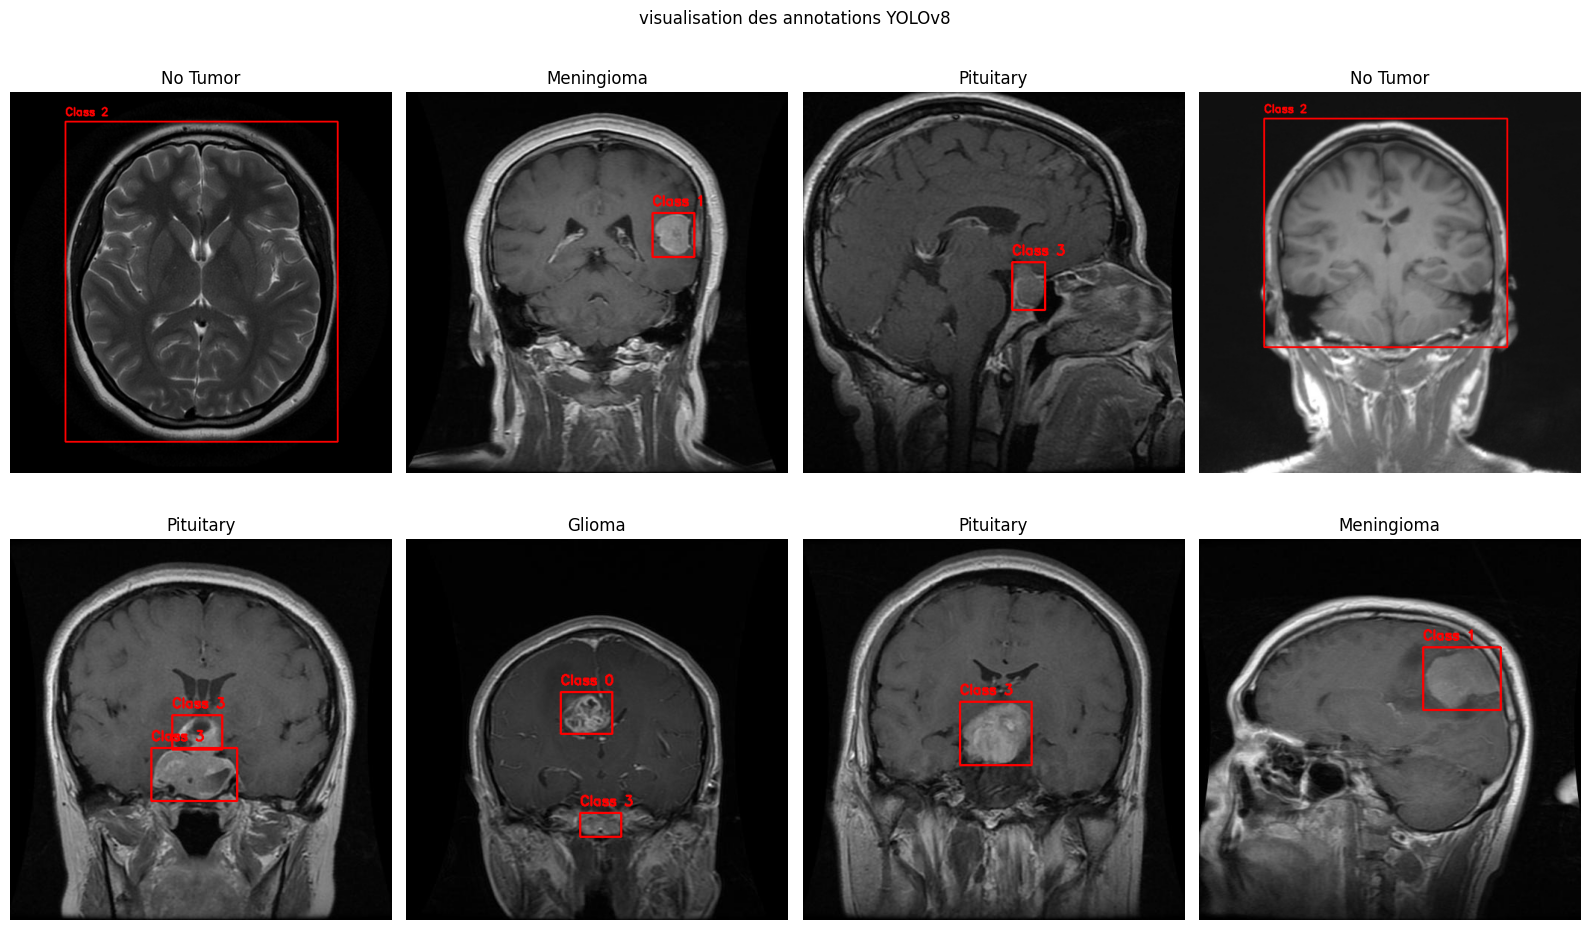

In [19]:
# echantillon
samples = []

for class_name in CLASS_NAMES:

    images_dir = TRAIN_SOURCE / class_name / "images"
    labels_dir = TRAIN_SOURCE / class_name / "labels"

    for image_path in sorted(images_dir.iterdir()):

        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        label_path = labels_dir / f"{image_path.stem}.txt"

        if label_path.exists():
            samples.append((image_path, label_path))

# 8 images aleatoire
selected_samples = random.sample(
    samples,
    min(8, len(samples))
)

fig, axes = plt.subplots(2, 4, figsize=(16, 10))
axes = axes.flatten()

for ax, (image_path, label_path) in zip(axes, selected_samples):

    image = visualize_yolo_image(image_path, label_path)

    if image is not None:
        ax.imshow(image)
        ax.set_title(image_path.parent.parent.name)
        ax.axis("off")

plt.suptitle("visualisation des annotations YOLOv8")
plt.tight_layout()
plt.show()

In [20]:
# la creation du strucutre
OUTPUT_DIR = Path("/kaggle/working/brainscan_yolo")

for folder in ["images/train", "images/valid", "images/test",
               "labels/train", "labels/valid", "labels/test"]:

    (OUTPUT_DIR / folder).mkdir(parents=True, exist_ok=True)


In [21]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def get_pairs(split_dir):
    pairs = []

    for class_name in CLASS_NAMES:
        images_dir = split_dir / class_name / "images"
        labels_dir = split_dir / class_name / "labels"

        # associer les annotations par nom
        labels = {p.stem: p for p in labels_dir.glob("*.txt")}

        for image_path in images_dir.iterdir():
            if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue

            label_path = labels.get(image_path.stem)

            # garder seulement les images avec annotation
            if label_path is not None:
                pairs.append((image_path, label_path, class_name))

    return pairs


train_pairs = get_pairs(TRAIN_SOURCE)
valid_pairs = get_pairs(VAL_SOURCE)

print("images train :", len(train_pairs))
print("images val :", len(valid_pairs))

images train : 4737
images val : 510


In [22]:
# ajout du test
train_pairs, test_pairs = train_test_split(
    train_pairs,
    test_size=0.15,
    random_state=42,
    stratify=[pair[2] for pair in train_pairs]
)

print("Train :", len(train_pairs))
print("Validation :", len(valid_pairs))
print("Test :", len(test_pairs))

Train : 4026
Validation : 510
Test : 711


In [23]:
# copier les imgs + transformer les annotations
# correspondance des anciennes et nouvelles classes
class_mapping = {
    0: 0,  # glioma
    1: 1,  # meningioma
    3: 2   # pituitary
}

def copy_dataset(pairs, split):
    for image_path, label_path, class_name in pairs:

        # nom unique du fichier
        new_name = f"{class_name}_{image_path.stem}"

        # copier l'image
        destination_image = OUTPUT_DIR / "images" / split / f"{new_name}{image_path.suffix}"
        shutil.copy2(image_path, destination_image)

        # creer le nouveau fichier d'annotation
        destination_label = OUTPUT_DIR / "labels" / split / f"{new_name}.txt"

        if class_name == "No Tumor":
            # aucun objet a detecter
            destination_label.write_text("")
        else:
            new_lines = []

            with open(label_path, "r") as file:
                for line in file:
                    values = line.strip().split()

                    if not values:
                        continue

                    old_id = int(values[0])

                    if old_id not in class_mapping:
                        raise ValueError(
                            f"id inattendu {old_id} dans {label_path}"
                        )

                    new_id = class_mapping[old_id]
                    new_lines.append(
                        " ".join([str(new_id)] + values[1:])
                    )

            destination_label.write_text(
                "\n".join(new_lines)
            )


# copier les trois ensembles
copy_dataset(train_pairs, "train")
copy_dataset(valid_pairs, "valid")
copy_dataset(test_pairs, "test")

print("copie terminee ")

copie terminee 


In [24]:
for split in ["train", "valid", "test"]:

    images = list((OUTPUT_DIR / "images" / split).glob("*"))
    labels = list((OUTPUT_DIR / "labels" / split).glob("*.txt"))

    print(f"\n{split.upper()}")
    print("Images :", len(images))
    print("Annotations :", len(labels))


TRAIN
Images : 4026
Annotations : 4026

VALID
Images : 510
Annotations : 510

TEST
Images : 711
Annotations : 711


In [25]:
# creer le file .yaml
import yaml

# configuration du dataset
data_config = {
    "path": str(OUTPUT_DIR),
    "train": "images/train",
    "val": "images/valid",
    "test": "images/test",
    "nc": 3,
    "names": {
        0: "Glioma",
        1: "Meningioma",
        2: "Pituitary"
    }
}

# sauvegarder la configuration
yaml_path = OUTPUT_DIR / "data.yaml"

with open(yaml_path, "w") as file:
    yaml.dump(data_config, file, sort_keys=False)

print("fichier data.yaml cree :", yaml_path)

fichier data.yaml cree : /kaggle/working/brainscan_yolo/data.yaml


In [26]:
!pip install ultralytics -q
import ultralytics

print("Ultralytics version :", ultralytics.__version__)

Ultralytics version : 8.4.197


In [27]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

In [28]:
print("data.yaml existe :", yaml_path.exists())

data.yaml existe : True


In [29]:
results = model.train(
    data=str(yaml_path),

    epochs=50,
    imgsz=640,
    batch=16,

    device=0,
    workers=2,

    optimizer="AdamW",
    lr0=0.001,

    patience=10,

    degrees=10,
    translate=0.1,
    scale=0.3,
    fliplr=0.5,

    pretrained=True,
    amp=True,
    cache=False,

    project=str(OUTPUT_DIR / "runs"),
    name="yolov8n_brainscan",

    seed=42,
    plots=True,
    save=True
)

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/brainscan_yolo/data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_brainscan, nbs=64, nms=None, opset=None,

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      2.61G      1.242      1.313      1.353         14        640: 100% ━━━━━━━━━━━━ 252/252 8.7it/s 29.1s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 6.3it/s 2.5s0.1s
                   all        510        456      0.771      0.648      0.743      0.447

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      2.61G      1.232      1.185      1.306          9        640: 100% ━━━━━━━━━━━━ 252/252 8.9it/s 28.4s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 6.0it/s 2.7s0.2s
                   all        510        456      0.833      0.755      0.836      0.547

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      2.61G      1.187       1.08      1.274         11        640: 100% ━━━━━━━━━━━━ 252/252 8.9it/s 28.4s0.2ss
                 Class     Ima

In [31]:
from ultralytics import YOLO

# charger le meilleur modele
best_model = YOLO(
    "/kaggle/working/brainscan_yolo/runs/yolov8n_brainscan/weights/best.pt"
)


In [32]:
# evaluer sur le test
test_results = best_model.val(
    data="/kaggle/working/brainscan_yolo/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 834.8±408.4 MB/s, size: 24.5 KB)
val: Scanning /kaggle/working/brainscan_yolo/labels/test... 711 images, 107 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 711/711 1.4Kit/s 0.5s0.0s
val: New cache created: /kaggle/working/brainscan_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 7.3it/s 6.1s0.2s
                   all        711        689       0.92      0.888      0.949      0.625
                Glioma        173        204      0.885      0.833      0.908      0.561
            Meningioma        216        222      0.959      0.977      0.992      0.697
             Pituitary        252        263      0.915      0.852      0.948      0.618
Speed: 1.2ms preprocess, 3.9ms inference, 0.0ms l

In [34]:
#metriques
metrics = {
    "Precision": test_results.box.mp,
    "Recall": test_results.box.mr,
    "mAP50": test_results.box.map50,
    "mAP50-95": test_results.box.map
}

for name, value in metrics.items():
    print(f"{name}: {value:.4f} ({value * 100:.2f}%)")

Precision: 0.9196 (91.96%)
Recall: 0.8875 (88.75%)
mAP50: 0.9489 (94.89%)
mAP50-95: 0.6251 (62.51%)


In [36]:
import pandas as pd

# sauvegarder les metriques
df_metrics = pd.DataFrame([metrics])

df_metrics.to_csv(
    "/kaggle/working/yolo_test_metrics.csv",
    index=False
)

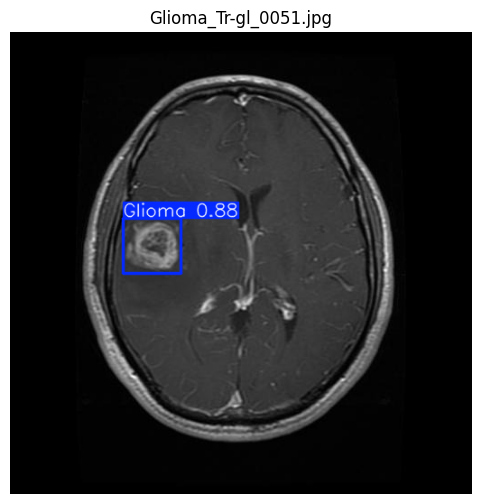

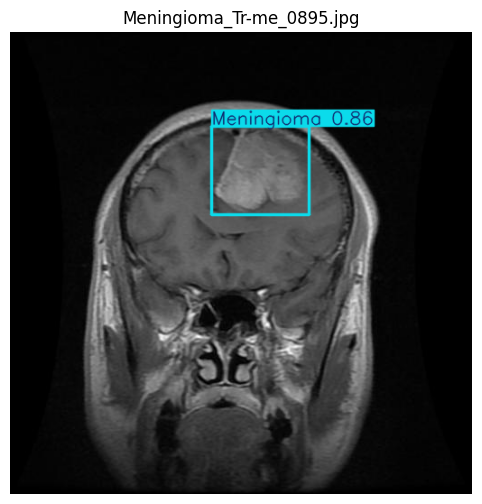

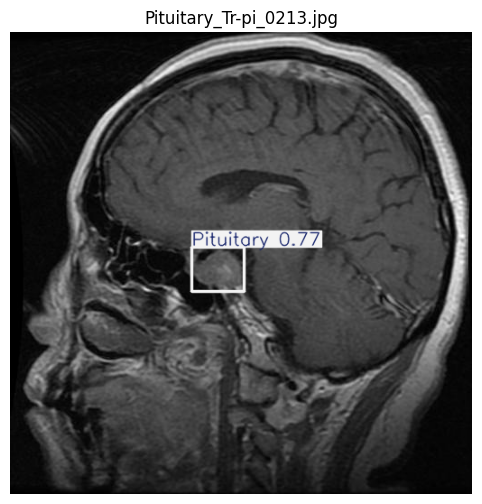

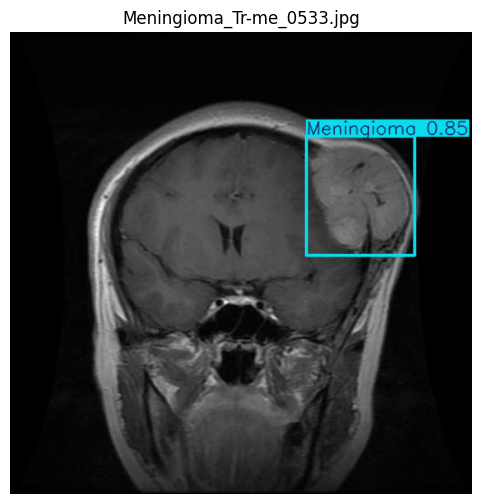

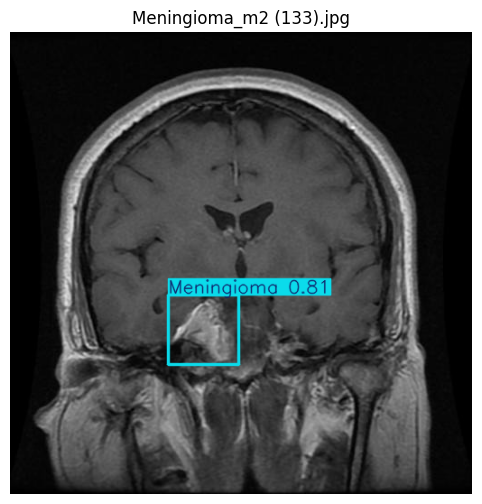

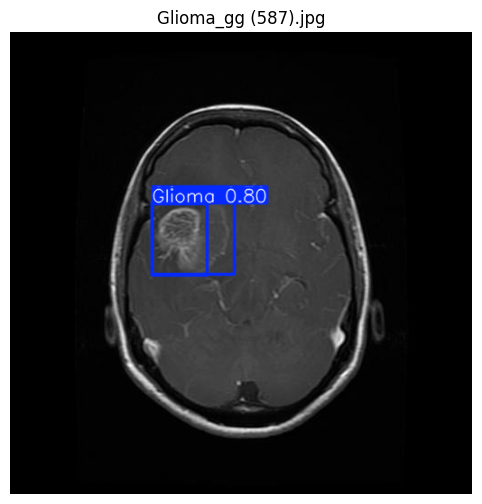

In [37]:
import matplotlib.pyplot as plt
from pathlib import Path
import random

test_images = list(
    Path("/kaggle/working/brainscan_yolo/images/test").glob("*")
)

selected_images = random.sample(test_images, min(6, len(test_images)))

for image_path in selected_images:
    results = best_model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )

    plotted_image = results[0].plot()

    plt.figure(figsize=(8, 6))
    plt.imshow(
        plotted_image[:, :, ::-1]
    )
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()

In [40]:
metrics_path = Path("/kaggle/working/yolo_test_metrics.csv")

print("fichier existe :", metrics_path.exists())

fichier existe : True


In [42]:
import shutil

shutil.copy2(
    weights_dir / "best.pt",
    "/kaggle/working/brainscan_yolo_best.pt"
)

print("meilleur modele sauvegarde")

meilleur modele sauvegarde


In [43]:
from ultralytics import YOLO

best_model = YOLO(
    "/kaggle/working/brainscan_yolo_best.pt"
)

best_model.export(
    format="onnx",
    imgsz=640,
    simplify=True
)

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/kaggle/working/brainscan_yolo_best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (6.2 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 212ms
Prepared 2 packages in 219ms
Installed 2 packages in 16ms
 + onnxruntime==1.31.1
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 0.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 2.3s, saved as '/kagg

'/kaggle/working/brainscan_yolo_best.onnx'

In [45]:
from ultralytics import YOLO

onnx_model = YOLO(
    "/kaggle/working/brainscan_yolo_best.onnx",
    task="detect"
)

print("Modele ONNX charge avec succes !")

Modele ONNX charge avec succes !


In [46]:
from pathlib import Path

test_images = list(
    Path("/kaggle/working/brainscan_yolo/images/test").glob("*")
)

image_path = str(test_images[0])

onnx_results = onnx_model.predict(
    source=image_path,
    imgsz=640,
    conf=0.25,
    verbose=False
)

print(onnx_results[0].boxes)

Loading /kaggle/working/brainscan_yolo_best.onnx for ONNX Runtime inference...
requirements: Ultralytics requirement ['onnxruntime-gpu[cuda]'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 10 packages in 149ms
Prepared 6 packages in 4.56s
Installed 6 packages in 47ms
 + nvidia-cuda-nvrtc==13.4.92
 + nvidia-cuda-runtime==13.4.92
 + nvidia-cufft==12.4.0.43
 + nvidia-curand==10.4.4.72
 + nvidia-nvjitlink==13.4.92
 + onnxruntime-gpu==1.31.1

requirements: AutoUpdate success ✅ 4.9s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Using ONNX Runtime 1.31.1 with CPUExecutionProvider
WARNING ⚠️ CUDA requested but CUDAExecutionProvider not available. Using CPU...
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([1.])
conf: tensor([0.8721])
data: tensor([[346.6251, 118.1987, 410.6428, 186.4946,   0.8721,   1.0000]])
id: None
is_track: False
orig_shape: (512, 512)
shape: torch.Size([1, 6])
xywh: ten

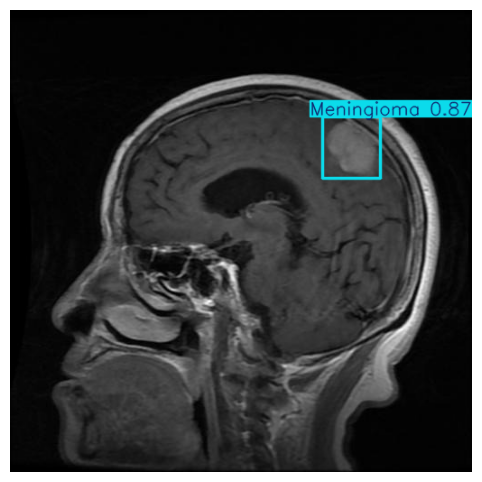

In [47]:
import matplotlib.pyplot as plt

result_image = onnx_results[0].plot()

plt.figure(figsize=(8, 6))
plt.imshow(result_image[:, :, ::-1])
plt.axis("off")
plt.show()


In [48]:
from pathlib import Path
import shutil

final_dir = Path("/kaggle/working/YOLOv8_Livrables")
final_dir.mkdir(exist_ok=True)

files_to_copy = [
    Path("/kaggle/working/brainscan_yolo_best.pt"),
    Path("/kaggle/working/brainscan_yolo_best.onnx"),
    Path("/kaggle/working/yolo_test_metrics.csv"),
    Path("/kaggle/working/brainscan_yolo/data.yaml")
]

for file in files_to_copy:
    if file.exists():
        shutil.copy2(file, final_dir / file.name)
        print("Copie :", file.name)
    else:
        print("fichier introuvable :", file)

Copie : brainscan_yolo_best.pt
Copie : brainscan_yolo_best.onnx
Copie : yolo_test_metrics.csv
Copie : data.yaml


In [49]:
import shutil

zip_path = shutil.make_archive(
    "/kaggle/working/YOLOv8_Livrables",
    "zip",
    "/kaggle/working/YOLOv8_Livrables"
)

print("archive creee :", zip_path)

archive creee : /kaggle/working/YOLOv8_Livrables.zip
